# Lab 2 – Deep Learning & Applications
**Part 1: CNN Classifier on MNIST (PyTorch, GPU mode)**

Pipeline:
1. Custom CNN (convolution, pooling, fully connected, dropout, L2 regularisation)
2. Faster R-CNN (torchvision) adapted to MNIST digit classification
3. Comparison (Accuracy, F1-score, Loss, Training time)
4. Fine-tuning pretrained **VGG16** and **AlexNet**, then final comparison and conclusion


## 0. Setup

In [ ]:
import time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models
import torchvision.transforms.functional as TF
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (enable a GPU!)")

# ---- Global configuration (reduce for quick tests, increase for the final run) ----
CFG = dict(
    cnn_epochs=5,  cnn_bs=128, cnn_lr=1e-3,
    frcnn_epochs=3, frcnn_bs=16, frcnn_lr=5e-3, frcnn_train_n=6000, frcnn_test_n=1000, frcnn_size=128,
    ft_epochs=3, ft_bs=128, ft_lr=1e-3, ft_train_n=12000, ft_test_n=10000, ft_size=64,
    num_workers=2,
)
RESULTS = {}   # model name -> metrics

Device: cuda | Tesla T4


## 1. Data loading & exploration

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.80MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.0MB/s]


60000 train images | 10000 test images


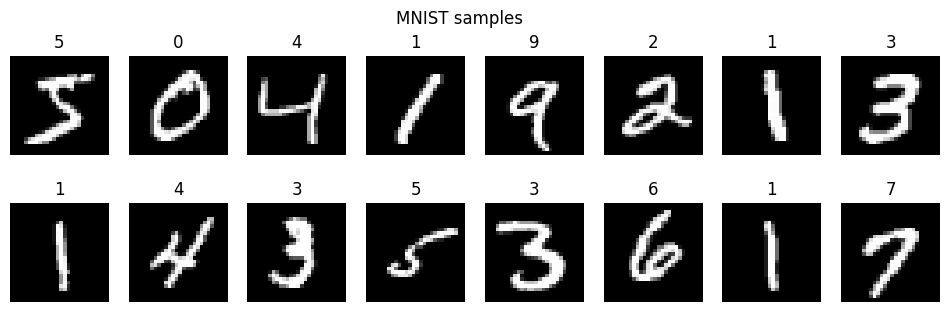

In [ ]:
mnist_train_raw = datasets.MNIST("./data", train=True,  download=True)
mnist_test_raw  = datasets.MNIST("./data", train=False, download=True)
print(len(mnist_train_raw), "train images |", len(mnist_test_raw), "test images")

fig, ax = plt.subplots(2, 8, figsize=(12, 3.5))
for i, a in enumerate(ax.flat):
    img, lbl = mnist_train_raw[i]
    a.imshow(img, cmap="gray"); a.set_title(lbl); a.axis("off")
plt.suptitle("MNIST samples"); plt.show()

## 2. Reusable training / evaluation utilities
Common functions used by the custom CNN, VGG16 and AlexNet (Faster R-CNN has its own loop because detection models use a different API).

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, preds, trues = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); trues.append(y.cpu())
    preds, trues = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    return dict(loss=total_loss / len(trues),
                acc=accuracy_score(trues, preds),
                f1=f1_score(trues, preds, average="macro")), preds, trues


def train_classifier(model, train_loader, test_loader, epochs, lr, name,
                     weight_decay=1e-4, params=None):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(params if params is not None else model.parameters(),
                                 lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, epochs // 2), gamma=0.5)
    hist = dict(train_loss=[], test_loss=[], test_acc=[], test_f1=[])

    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            run += loss.item() * x.size(0)
        scheduler.step()
        m, _, _ = evaluate(model, test_loader, criterion)
        hist["train_loss"].append(run / len(train_loader.dataset))
        hist["test_loss"].append(m["loss"]); hist["test_acc"].append(m["acc"]); hist["test_f1"].append(m["f1"])
        print(f"[{name}] epoch {ep}/{epochs} | train loss {hist['train_loss'][-1]:.4f} | "
              f"test loss {m['loss']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - t0

    final, preds, trues = evaluate(model, test_loader, criterion)
    final["train_time_s"] = train_time
    final["params_M"] = sum(p.numel() for p in model.parameters()) / 1e6
    RESULTS[name] = final
    return model, hist, preds, trues


def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"{title} – loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["test_acc"], label="accuracy"); ax[1].plot(hist["test_f1"], label="macro F1")
    ax[1].set_title(f"{title} – test metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()


def plot_confusion(trues, preds, title, labels=range(10)):
    cm = confusion_matrix(trues, preds, labels=list(labels))
    plt.figure(figsize=(5, 4.5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.title(f"Confusion matrix – {title}"); plt.xlabel("predicted"); plt.ylabel("true")
    plt.xticks(range(len(cm))); plt.yticks(range(len(cm))); plt.show()

## 3. Task 1 – Custom CNN (PyTorch, GPU)

**Architecture** (input 1×28×28):

| Layer | Hyper-parameters | Output |
|---|---|---|
| Conv1 + BN + ReLU + MaxPool | 32 kernels 3×3, stride 1, padding 1; pool 2×2 | 32×14×14 |
| Conv2 + BN + ReLU + MaxPool | 64 kernels 3×3, stride 1, padding 1; pool 2×2 | 64×7×7 |
| Conv3 + BN + ReLU + MaxPool | 128 kernels 3×3, stride 1, padding 1; pool 2×2 | 128×3×3 |
| FC1 + ReLU + Dropout(0.5) | 1152 → 256 | 256 |
| FC2 | 256 → 10 | 10 |

Output size formula: `(n + 2p − f)/s + 1`. **Optimizer:** Adam (lr 1e-3) with L2 regularisation (`weight_decay=1e-4`), Dropout and BatchNorm, StepLR scheduler.

In [ ]:
tf_cnn = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_ds = datasets.MNIST("./data", train=True,  transform=tf_cnn)
test_ds  = datasets.MNIST("./data", train=False, transform=tf_cnn)
train_loader = DataLoader(train_ds, batch_size=CFG["cnn_bs"], shuffle=True,  num_workers=CFG["num_workers"], pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=512,           shuffle=False, num_workers=CFG["num_workers"], pin_memory=True)

class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, kernel_size=3, stride=1, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 3 * 3, 256), nn.ReLU(),
                                        nn.Dropout(0.5), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = CNN()
print(cnn)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-

[CNN (custom)] epoch 1/5 | train loss 0.1578 | test loss 0.0399 | acc 0.9863 | F1 0.9862
[CNN (custom)] epoch 2/5 | train loss 0.0527 | test loss 0.0267 | acc 0.9914 | F1 0.9914
[CNN (custom)] epoch 3/5 | train loss 0.0293 | test loss 0.0220 | acc 0.9924 | F1 0.9924
[CNN (custom)] epoch 4/5 | train loss 0.0236 | test loss 0.0185 | acc 0.9936 | F1 0.9935
[CNN (custom)] epoch 5/5 | train loss 0.0145 | test loss 0.0186 | acc 0.9949 | F1 0.9949


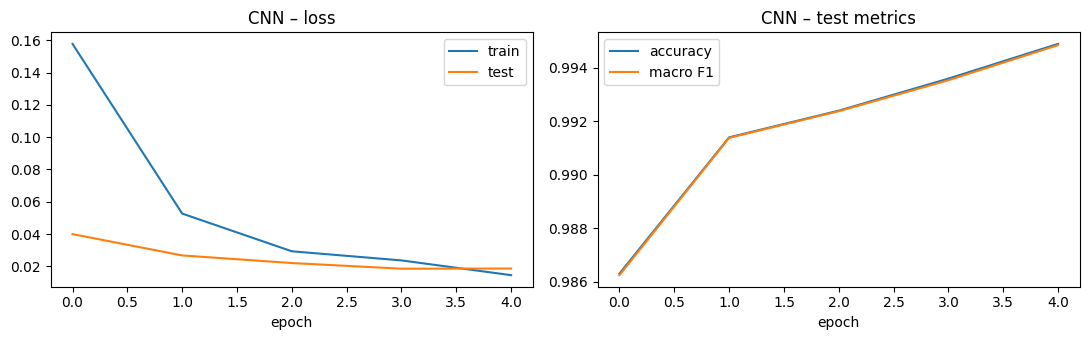

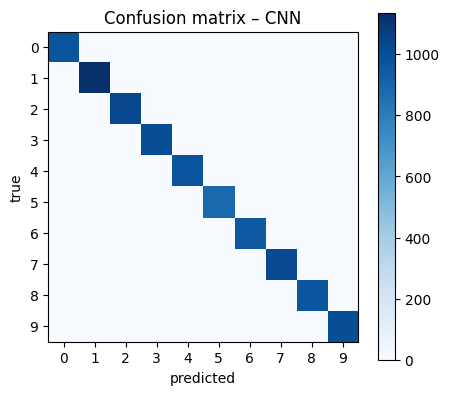

{'loss': 0.01861605256795883, 'acc': 0.9949, 'f1': 0.9948547212562872, 'train_time_s': 85.13660788536072, 'params_M': 0.390858}


In [ ]:
cnn, hist_cnn, preds_cnn, trues_cnn = train_classifier(
    cnn, train_loader, test_loader, CFG["cnn_epochs"], CFG["cnn_lr"], name="CNN (custom)")
plot_history(hist_cnn, "CNN")
plot_confusion(trues_cnn, preds_cnn, "CNN")
print(RESULTS["CNN (custom)"])

## 4. Task 2 – Faster R-CNN on MNIST

Faster R-CNN is an **object detector** (Region Proposal Network + RoI head). To use it on MNIST we turn each image into a detection sample:
* the **bounding box** is the tight box around the non-zero pixels of the digit,
* the **label** is the digit class (+1, because label 0 is reserved for the background → 11 classes),
* images are resized to 128×128 and replicated to 3 channels.

At inference, the **class of the highest-scoring detected box** is the predicted digit (no detection → counted as an error).
To keep training time reasonable we use the lightweight `fasterrcnn_mobilenet_v3_large_fpn` backbone and a subset of MNIST (see `CFG`).

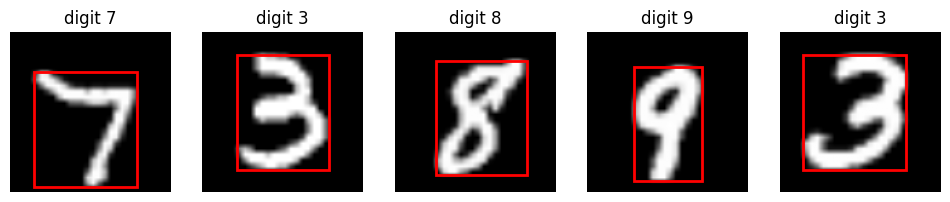

In [ ]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

class MNISTDetection(Dataset):
    def __init__(self, base, indices, size=128):
        self.base, self.indices, self.size = base, indices, size
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        img, label = self.base[self.indices[i]]
        t = TF.to_tensor(img)                                  # 1x28x28 in [0,1]
        ys, xs = torch.where(t[0] > 0.1)
        s = self.size / 28.0
        box = torch.tensor([[xs.min().item(), ys.min().item(),
                             xs.max().item() + 1, ys.max().item() + 1]], dtype=torch.float32) * s
        t = TF.resize(t, [self.size, self.size], antialias=True).repeat(3, 1, 1)
        return t, {"boxes": box, "labels": torch.tensor([label + 1], dtype=torch.int64)}

def collate(batch): return tuple(zip(*batch))

rng = np.random.RandomState(SEED)
tr_idx = rng.choice(len(mnist_train_raw), CFG["frcnn_train_n"], replace=False)
te_idx = rng.choice(len(mnist_test_raw),  CFG["frcnn_test_n"],  replace=False)
det_train = DataLoader(MNISTDetection(mnist_train_raw, tr_idx, CFG["frcnn_size"]), batch_size=CFG["frcnn_bs"],
                       shuffle=True, collate_fn=collate, num_workers=CFG["num_workers"])
det_test  = DataLoader(MNISTDetection(mnist_test_raw,  te_idx, CFG["frcnn_size"]), batch_size=CFG["frcnn_bs"],
                       shuffle=False, collate_fn=collate, num_workers=CFG["num_workers"])

# visual check of boxes
import matplotlib.patches as patches
fig, ax = plt.subplots(1, 5, figsize=(12, 3))
ds_vis = det_train.dataset
for a, i in zip(ax, range(5)):
    im, tg = ds_vis[i]; a.imshow(im[0], cmap="gray")
    x1, y1, x2, y2 = tg["boxes"][0].tolist()
    a.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", lw=2))
    a.set_title(f"digit {tg['labels'].item() - 1}"); a.axis("off")
plt.show()

[Faster R-CNN] epoch 1/3 | train loss 1.2678 | test loss 1.1514 | acc 0.8540 | F1 0.8486
[Faster R-CNN] epoch 2/3 | train loss 0.7139 | test loss 0.6156 | acc 0.9630 | F1 0.9627
[Faster R-CNN] epoch 3/3 | train loss 0.5274 | test loss 0.5326 | acc 0.9600 | F1 0.9595


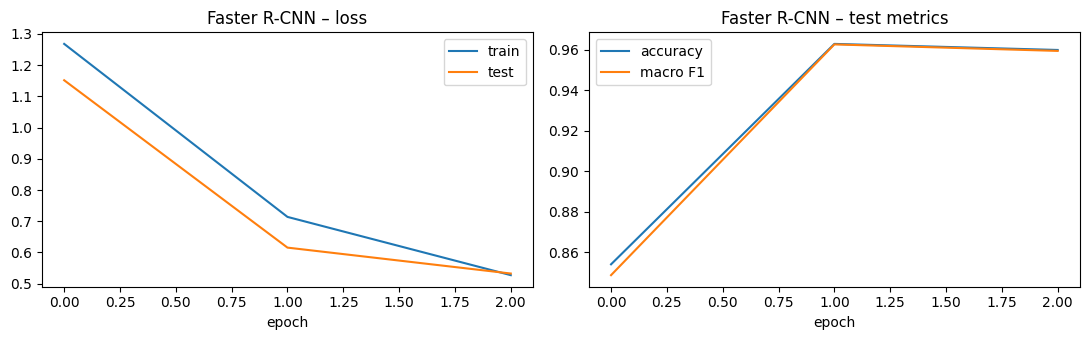

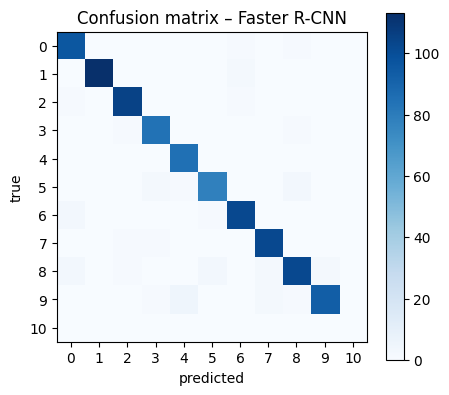

{'loss': 0.5326044130325317, 'acc': 0.96, 'f1': 0.9595313587249059, 'train_time_s': 215.00129556655884, 'params_M': 18.976354}


In [ ]:
def build_frcnn(num_classes=11, size=128, pretrained_backbone=True):
    # pretrained_backbone=True downloads ImageNet weights for the MobileNetV3 backbone (faster convergence)
    model = fasterrcnn_mobilenet_v3_large_fpn(
        weights=None, weights_backbone="DEFAULT" if pretrained_backbone else None,
        min_size=size, max_size=size, box_detections_per_img=10)
    in_feat = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_feat, num_classes)
    return model

@torch.no_grad()
def evaluate_frcnn(model, loader):
    # classification metrics (top-scoring box) + detection loss (computed in train mode, no gradients)
    model.eval(); preds, trues = [], []
    for imgs, tgts in loader:
        outs = model([i.to(device) for i in imgs])
        for o, t in zip(outs, tgts):
            preds.append(o["labels"][o["scores"].argmax()].item() - 1 if len(o["boxes"]) else 10)  # 10 = "no detection"
            trues.append(t["labels"].item() - 1)
    model.train(); loss_sum, n = 0.0, 0
    for imgs, tgts in loader:
        ld = model([i.to(device) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tgts])
        loss_sum += sum(ld.values()).item() * len(imgs); n += len(imgs)
    model.eval()
    return dict(loss=loss_sum / n, acc=accuracy_score(trues, preds),
                f1=f1_score(trues, preds, average="macro", labels=list(range(10)))), preds, trues

frcnn = build_frcnn(size=CFG["frcnn_size"]).to(device)
params = [p for p in frcnn.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=CFG["frcnn_lr"], momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, CFG["frcnn_epochs"] // 2), gamma=0.1)

hist_fr = dict(train_loss=[], test_loss=[], test_acc=[], test_f1=[])
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
for ep in range(1, CFG["frcnn_epochs"] + 1):
    frcnn.train(); run, n = 0.0, 0
    for imgs, tgts in det_train:
        imgs = [i.to(device) for i in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        loss = sum(frcnn(imgs, tgts).values())
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        run += loss.item() * len(imgs); n += len(imgs)
    scheduler.step()
    m, _, _ = evaluate_frcnn(frcnn, det_test)
    hist_fr["train_loss"].append(run / n); hist_fr["test_loss"].append(m["loss"])
    hist_fr["test_acc"].append(m["acc"]); hist_fr["test_f1"].append(m["f1"])
    print(f"[Faster R-CNN] epoch {ep}/{CFG['frcnn_epochs']} | train loss {run/n:.4f} | "
          f"test loss {m['loss']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f}")
if device.type == "cuda": torch.cuda.synchronize()
frcnn_time = time.time() - t0

final, preds_fr, trues_fr = evaluate_frcnn(frcnn, det_test)
final["train_time_s"] = frcnn_time
final["params_M"] = sum(p.numel() for p in frcnn.parameters()) / 1e6
RESULTS["Faster R-CNN"] = final
plot_history(hist_fr, "Faster R-CNN")
plot_confusion(trues_fr, preds_fr, "Faster R-CNN", labels=range(11))
print(final)

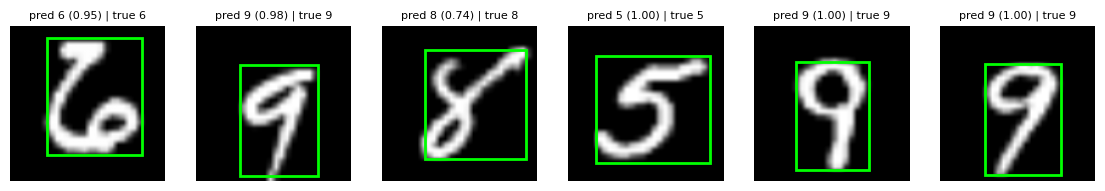

In [ ]:
# Qualitative results: predicted boxes + class
frcnn.eval()
fig, ax = plt.subplots(1, 6, figsize=(14, 3))
with torch.no_grad():
    for a, i in zip(ax, range(6)):
        im, tg = det_test.dataset[i]
        o = frcnn([im.to(device)])[0]
        a.imshow(im[0], cmap="gray"); a.axis("off")
        if len(o["boxes"]):
            x1, y1, x2, y2 = o["boxes"][0].cpu().tolist()
            a.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", lw=2))
            a.set_title(f"pred {o['labels'][0].item()-1} ({o['scores'][0]:.2f}) | true {tg['labels'].item()-1}", fontsize=8)
        else:
            a.set_title(f"no detection | true {tg['labels'].item()-1}", fontsize=8)
plt.show()

## 5. Task 3 – Comparison: CNN vs Faster R-CNN
Metrics: **Accuracy, macro F1-score, Loss, Training time** (also number of parameters).
> The Faster R-CNN loss is the detection loss (RPN + box regression + classification) and is not directly comparable to the cross-entropy of the classifiers; accuracy/F1/time are the fair comparison. Faster R-CNN is also trained on a subset (see `CFG`).

,Accuracy,F1 (macro),Loss,Train time (s),Params (M)
CNN (custom),0.9949,0.9949,0.0186,85.1366,0.3909
Faster R-CNN,0.9600,0.9595,0.5326,215.0013,18.9764
VGG16 (fine-tuned),0.9617,0.9615,0.1240,54.1456,134.3015
AlexNet (fine-tuned),0.9391,0.9382,0.1893,32.3225,57.0448


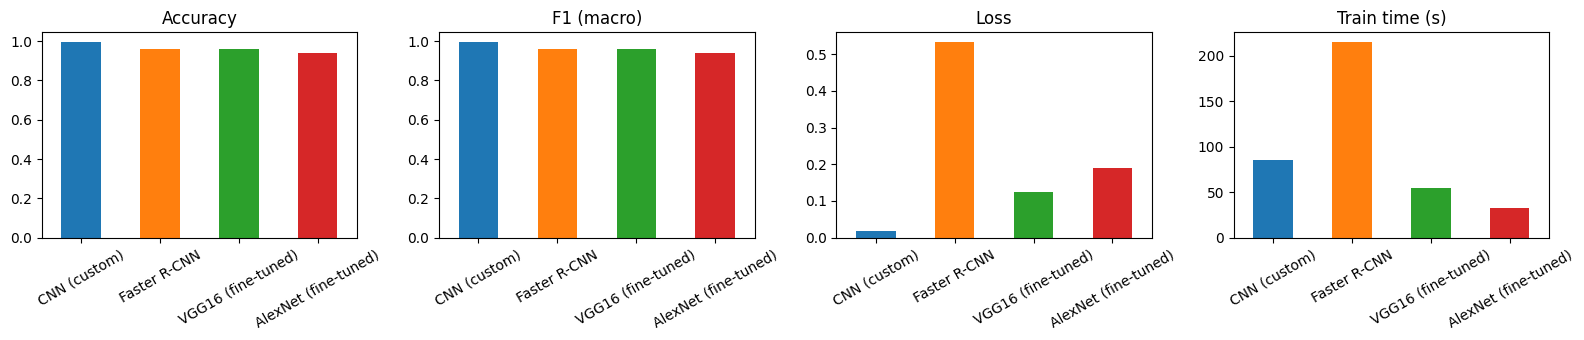

In [ ]:
def results_table():
    df = pd.DataFrame(RESULTS).T.rename(columns={"loss": "Loss", "acc": "Accuracy", "f1": "F1 (macro)",
                                                 "train_time_s": "Train time (s)", "params_M": "Params (M)"})
    return df[["Accuracy", "F1 (macro)", "Loss", "Train time (s)", "Params (M)"]].round(4)

display(results_table())

def plot_comparison():
    df = results_table()
    colors = list(plt.cm.tab10.colors[:len(df)])   # <-- fix: must be a list, not a tuple of tuples
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
    for a, col in zip(ax, ["Accuracy", "F1 (macro)", "Loss", "Train time (s)"]):
        df[col].plot(kind="bar", ax=a, color=colors); a.set_title(col)
        a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()
plot_comparison()

## 6. Task 4 – Fine-tuning pretrained VGG16 and AlexNet (ImageNet weights)

MNIST is adapted to the ImageNet models: images are resized (28→64), replicated to 3 channels and normalised with ImageNet statistics. The last fully-connected layer is replaced by a 10-class layer.

Two strategies are provided via `FREEZE_FEATURES`:
* `True`  – **feature extraction**: convolutional layers frozen, only the classifier is trained (fast),
* `False` – **full fine-tuning**: all layers trained with a small learning rate (slower, usually better).

In [ ]:
FREEZE_FEATURES = True   # set to False for full fine-tuning (use a smaller lr, e.g. 1e-4)

imagenet_norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_pre = transforms.Compose([transforms.Resize(CFG["ft_size"]), transforms.Grayscale(3),
                             transforms.ToTensor(), imagenet_norm])
pre_train = datasets.MNIST("./data", train=True,  transform=tf_pre)
pre_test  = datasets.MNIST("./data", train=False, transform=tf_pre)
rng = np.random.RandomState(SEED)
pre_train = Subset(pre_train, rng.choice(len(pre_train), CFG["ft_train_n"], replace=False))
pre_test  = Subset(pre_test,  rng.choice(len(pre_test),  CFG["ft_test_n"],  replace=False))
pre_train_loader = DataLoader(pre_train, batch_size=CFG["ft_bs"], shuffle=True,  num_workers=CFG["num_workers"], pin_memory=True)
pre_test_loader  = DataLoader(pre_test,  batch_size=256,          shuffle=False, num_workers=CFG["num_workers"], pin_memory=True)

def build_pretrained(name):
    if name == "vgg16":
        m = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    else:
        m = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
    if FREEZE_FEATURES:
        for p in m.features.parameters(): p.requires_grad = False
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 10)   # new head for 10 digits
    return m

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 98.8MB/s]


[VGG16 (fine-tuned)] epoch 1/3 | train loss 0.6425 | test loss 0.1884 | acc 0.9426 | F1 0.9420
[VGG16 (fine-tuned)] epoch 2/3 | train loss 0.1880 | test loss 0.1769 | acc 0.9448 | F1 0.9440
[VGG16 (fine-tuned)] epoch 3/3 | train loss 0.1346 | test loss 0.1240 | acc 0.9617 | F1 0.9615


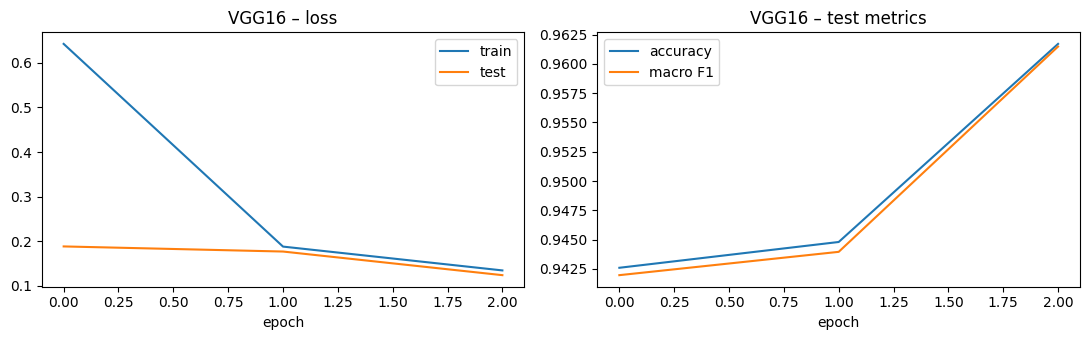

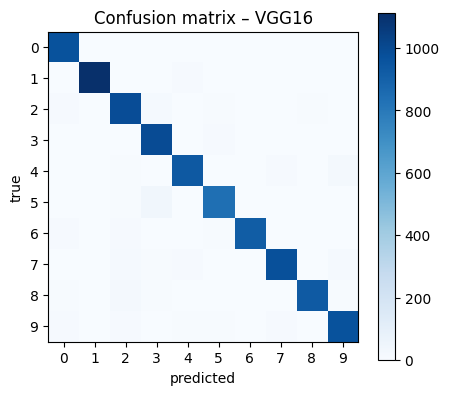

In [ ]:
vgg = build_pretrained("vgg16")
vgg, hist_vgg, preds_vgg, trues_vgg = train_classifier(
    vgg, pre_train_loader, pre_test_loader, CFG["ft_epochs"], CFG["ft_lr"], name="VGG16 (fine-tuned)",
    params=[p for p in vgg.parameters() if p.requires_grad])
plot_history(hist_vgg, "VGG16"); plot_confusion(trues_vgg, preds_vgg, "VGG16")
del vgg; torch.cuda.empty_cache() if device.type == "cuda" else None

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 168MB/s]


[AlexNet (fine-tuned)] epoch 1/3 | train loss 0.8005 | test loss 0.3129 | acc 0.8982 | F1 0.8976
[AlexNet (fine-tuned)] epoch 2/3 | train loss 0.3111 | test loss 0.2195 | acc 0.9261 | F1 0.9255
[AlexNet (fine-tuned)] epoch 3/3 | train loss 0.2310 | test loss 0.1893 | acc 0.9391 | F1 0.9382


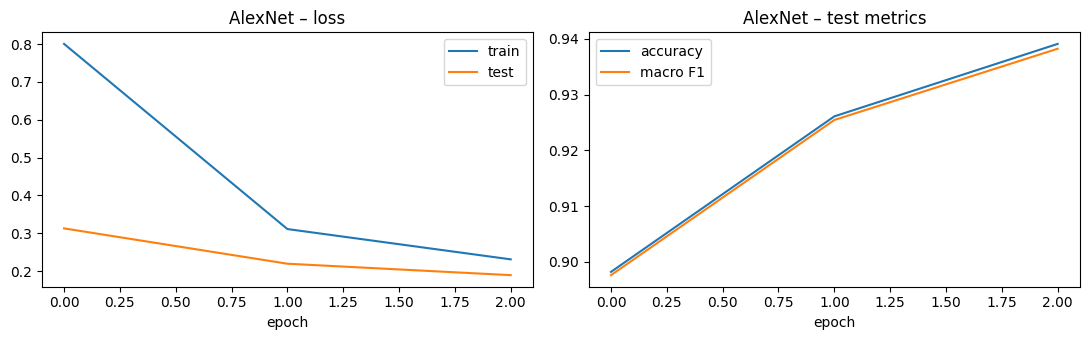

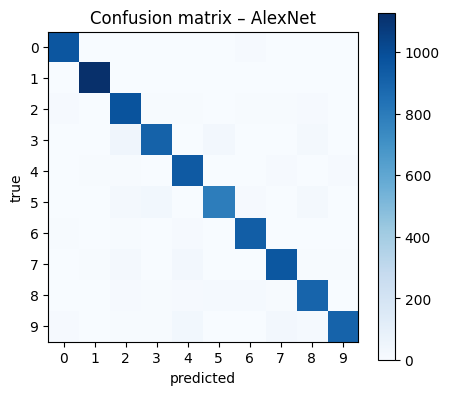

In [ ]:
alex = build_pretrained("alexnet")
alex, hist_alex, preds_alex, trues_alex = train_classifier(
    alex, pre_train_loader, pre_test_loader, CFG["ft_epochs"], CFG["ft_lr"], name="AlexNet (fine-tuned)",
    params=[p for p in alex.parameters() if p.requires_grad])
plot_history(hist_alex, "AlexNet"); plot_confusion(trues_alex, preds_alex, "AlexNet")

## 7. Final comparison – all models

,Accuracy,F1 (macro),Loss,Train time (s),Params (M)
CNN (custom),0.9949,0.9949,0.0186,85.1366,0.3909
Faster R-CNN,0.9600,0.9595,0.5326,215.0013,18.9764
VGG16 (fine-tuned),0.9617,0.9615,0.1240,54.1456,134.3015
AlexNet (fine-tuned),0.9391,0.9382,0.1893,32.3225,57.0448


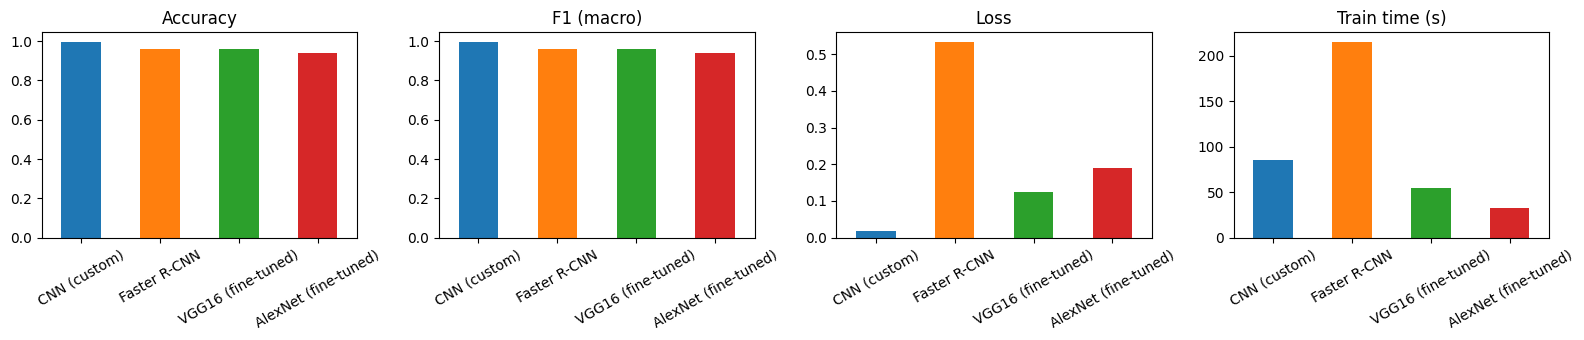

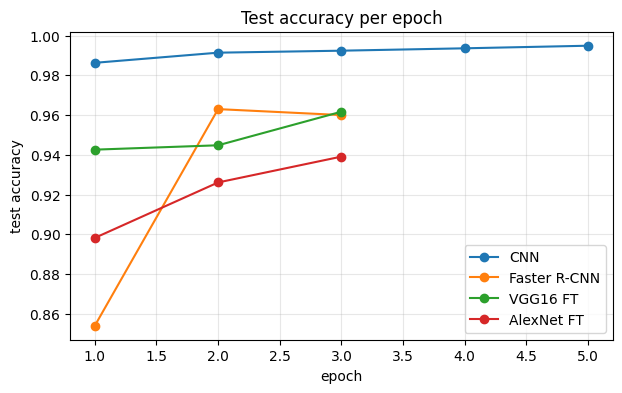

In [ ]:
df = results_table()
display(df)
plot_comparison()

# Learning curves of test accuracy for every model
plt.figure(figsize=(7, 4))
for h, n in [(hist_cnn, "CNN"), (hist_fr, "Faster R-CNN"), (hist_vgg, "VGG16 FT"), (hist_alex, "AlexNet FT")]:
    plt.plot(range(1, len(h["test_acc"]) + 1), h["test_acc"], marker="o", label=n)
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.title("Test accuracy per epoch"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 8. Conclusion

### Results

| Model | Accuracy | F1 (macro) | Loss | Train time (s) | Params (M) |
|---|---|---|---|---|---|
| **CNN (custom)** | **0.9949** | **0.9949** | **0.0186** | 85.1 | **0.39** |
| Faster R-CNN | 0.9600 | 0.9595 | 0.5326* | 215.0 | 18.98 |
| VGG16 (fine-tuned) | 0.9617 | 0.9615 | 0.1240 | 54.1 | 134.30 |
| AlexNet (fine-tuned) | 0.9391 | 0.9382 | 0.1893 | **32.3** | 57.04 |

\*Faster R-CNN loss is a detection loss (RPN + box + classification), so it is not directly comparable to the cross-entropy of the other models.

### Analysis

* **Custom CNN – best overall.** It reaches the highest accuracy and F1 (99.49 %) and the lowest loss (0.0186) with only 0.39 M parameters. It is trained from scratch on the full 60,000 images, and its train/test losses stay close, so regularisation (BatchNorm, Dropout, L2) works well and there is no overfitting.
* **Faster R-CNN – good but not worth the cost.** It reaches 96.0 % accuracy but takes the longest to train (215 s, 2.5× the CNN) and has 49× more parameters. On MNIST each image contains one centred digit, so the RPN and box regression bring no benefit, and classification accuracy is limited by the detector (a missed detection counts as an error). It was also trained on a subset for only 3 epochs.
* **VGG16 fine-tuned – best pretrained model.** 96.2 % accuracy, slightly above Faster R-CNN, but with 134 M parameters (344× the custom CNN). Its test loss was still decreasing at epoch 3, so more epochs or full fine-tuning would likely improve it.
* **AlexNet fine-tuned – fastest, least accurate.** The shortest training time (32 s) but the lowest accuracy (93.9 %) because of its smaller capacity. It also converged more slowly (89.8 % → 92.6 % → 93.9 %).
* **Why the pretrained models lag behind.** ImageNet features were learned on colour natural images, while MNIST digits are low-resolution grayscale. The images must be upscaled to 64×64 and replicated to 3 channels. The pretrained models were also trained on a subset (12,000 images) for only 3 epochs, whereas the CNN used the full dataset. These differences in training setup should be kept in mind when comparing.

### Final conclusion

For a simple, small, grayscale dataset like MNIST, **a well-designed small CNN trained from scratch gives the best trade-off between accuracy, model size and training time**: about 3 to 5 points more accurate than the other models, with 49 to 344 times fewer parameters. Transfer learning with VGG16 or AlexNet works (94 to 96 %) and converges quickly, but its large models are unnecessary here. Faster R-CNN is designed for localising several objects in a scene and is the wrong tool for plain digit classification. Pretrained and detection models become worthwhile on more complex data (natural images, small datasets, multi-object scenes).